In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

import scanpy as sc
import scvi
import pathlib
import warnings
warnings.filterwarnings('ignore')

sc.set_figure_params(figsize=(4, 4))

In [ ]:
annot = sc.queries.biomart_annotations(
        "hsapiens",
        ["ensembl_gene_id", "external_gene_name", "chromosome_name"],
    ).set_index("external_gene_name")

## Chaffin 2022

In [130]:
Chaffin = sc.read_h5ad("/rwthfs/rz/cluster/home/noco0013/projects/novo_postdoc/data/human_dcm_hcm_scportal_03.17.2022.h5ad")
sc.pp.filter_cells(Chaffin, min_genes=300)
sc.pp.filter_genes(Chaffin, min_cells=5)

In [131]:
Chaffin.X = Chaffin.layers["cellranger_raw"]

In [132]:
del Chaffin.layers
del Chaffin.obsm

In [133]:
Chaffin.X.data

array([2., 1., 1., ..., 1., 1., 1.], dtype=float32)

In [134]:
meta = pd.read_csv("Meta_data_Chaffin_.csv", index_col=0)
for col in meta:
    Chaffin.obs[col] = meta[col]

In [135]:
Chaffin.obs["Subcluster"] = Chaffin.obs["SubCluster"]

In [136]:
Chaffin.obs.drop(["biosample_id", "donor_id", "disease", "sex", "age", "lvef", "cell_type_leiden0.6", "cellbender_ncount", "cellbender_ngenes", "cellranger_percent_mito", "exon_prop", "cellbender_entropy", "cellranger_doublet_scores", "SubCluster"], axis=1, inplace=True)

In [137]:
Chaffin.obs


,n_genes,nCount_RNA,nFeature_RNA,Cell_type,Technology,Assay,Study,Tissue,Sex,Age,Donor,Condition,Genotype,SNP,Death,Doublets,Subcluster
TTCTTCCGTTCAACGT-1-0,4632,16248,4851,Cardiomyocyte_I,5v1,Nuclei,Chaffin 2022,Left Ventricle,Male,50-59,Ch_P1622,Healthy,NaN,NaN,In situ arrested,2.76,CM-X1
CATCCACCATCTAACG-1-0,4673,15865,4844,Cardiomyocyte_I,5v1,Nuclei,Chaffin 2022,Left Ventricle,Male,50-59,Ch_P1622,Healthy,NaN,NaN,In situ arrested,0.20,CM-HHATL
ACCCAAACAGCTAACT-1-0,4432,15320,4614,Cardiomyocyte_I,5v1,Nuclei,Chaffin 2022,Left Ventricle,Male,50-59,Ch_P1622,Healthy,NaN,NaN,In situ arrested,0.24,CM-HHATL
AAGGAATCAACTGGTT-1-0,4483,15305,4641,Cardiomyocyte_I,5v1,Nuclei,Chaffin 2022,Left Ventricle,Male,50-59,Ch_P1622,Healthy,NaN,NaN,In situ arrested,1.26,CM-X1
TACCCGTAGCGTGCTC-1-0,4690,15127,4852,Cardiomyocyte_I,5v1,Nuclei,Chaffin 2022,Left Ventricle,Male,50-59,Ch_P1622,Healthy,NaN,NaN,In situ arrested,0.12,CM-HHATL
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CATCCGTTCGCCGTGA-1-79,399,640,514,Endothelial_I,5v1,Nuclei,Chaffin 2022,Left Ventricle,Male,60-69,Ch_P1561,Healthy,A2ML1,chr12:8863966:GGC:G,In situ arrested,0.00,EC-X1
GTCACGGGTTGTATGC-1-79,349,619,444,Endothelial_I,5v1,Nuclei,Chaffin 2022,Left Ventricle,Male,60-69,Ch_P1561,Healthy,A2ML1,chr12:8863966:GGC:G,In situ arrested,0.00,EC-PKD1L1
GTCATGATCTTTCGAT-1-79,404,610,491,Endothelial_I,5v1,Nuclei,Chaffin 2022,Left Ventricle,Male,60-69,Ch_P1561,Healthy,A2ML1,chr12:8863966:GGC:G,In situ arrested,0.00,EC-Lymphatic
GCGATCGTCAGAGTGG-1-79,343,544,445,Endothelial_I,5v1,Nuclei,Chaffin 2022,Left Ventricle,Male,60-69,Ch_P1561,Healthy,A2ML1,chr12:8863966:GGC:G,In situ arrested,0.00,EC-Lymphatic


In [141]:
# Convert the index to a column called 'gene_symbol' but and use gene_id instead
Chaffin.var['gene_symbol'] = Chaffin.var.index
Chaffin.var.index = Chaffin.var['gene_ids']
Chaffin.var.drop(columns=['gene_ids'], inplace=True)
Chaffin.var

,feature_types,genome,n_cells,gene_symbol
gene_ids,,,,
ENSG00000238009,Gene Expression,GRCh38-2020-A_premrna,4463,AL627309.1
ENSG00000239906,Gene Expression,GRCh38-2020-A_premrna,37,AL627309.2
ENSG00000241860,Gene Expression,GRCh38-2020-A_premrna,5191,AL627309.5
ENSG00000241599,Gene Expression,GRCh38-2020-A_premrna,26,AL627309.4
ENSG00000286448,Gene Expression,GRCh38-2020-A_premrna,1043,AP006222.2
...,...,...,...,...
ENSG00000277761,Gene Expression,GRCh38-2020-A_premrna,29,AC136616.2
ENSG00000278633,Gene Expression,GRCh38-2020-A_premrna,13,AC023491.2
ENSG00000276017,Gene Expression,GRCh38-2020-A_premrna,64,AC007325.1


In [142]:
Chaffin.write("/rwthfs/rz/cluster/home/noco0013/projects/novo_postdoc/data/Heart/Chaffin_2022_raw.h5ad")

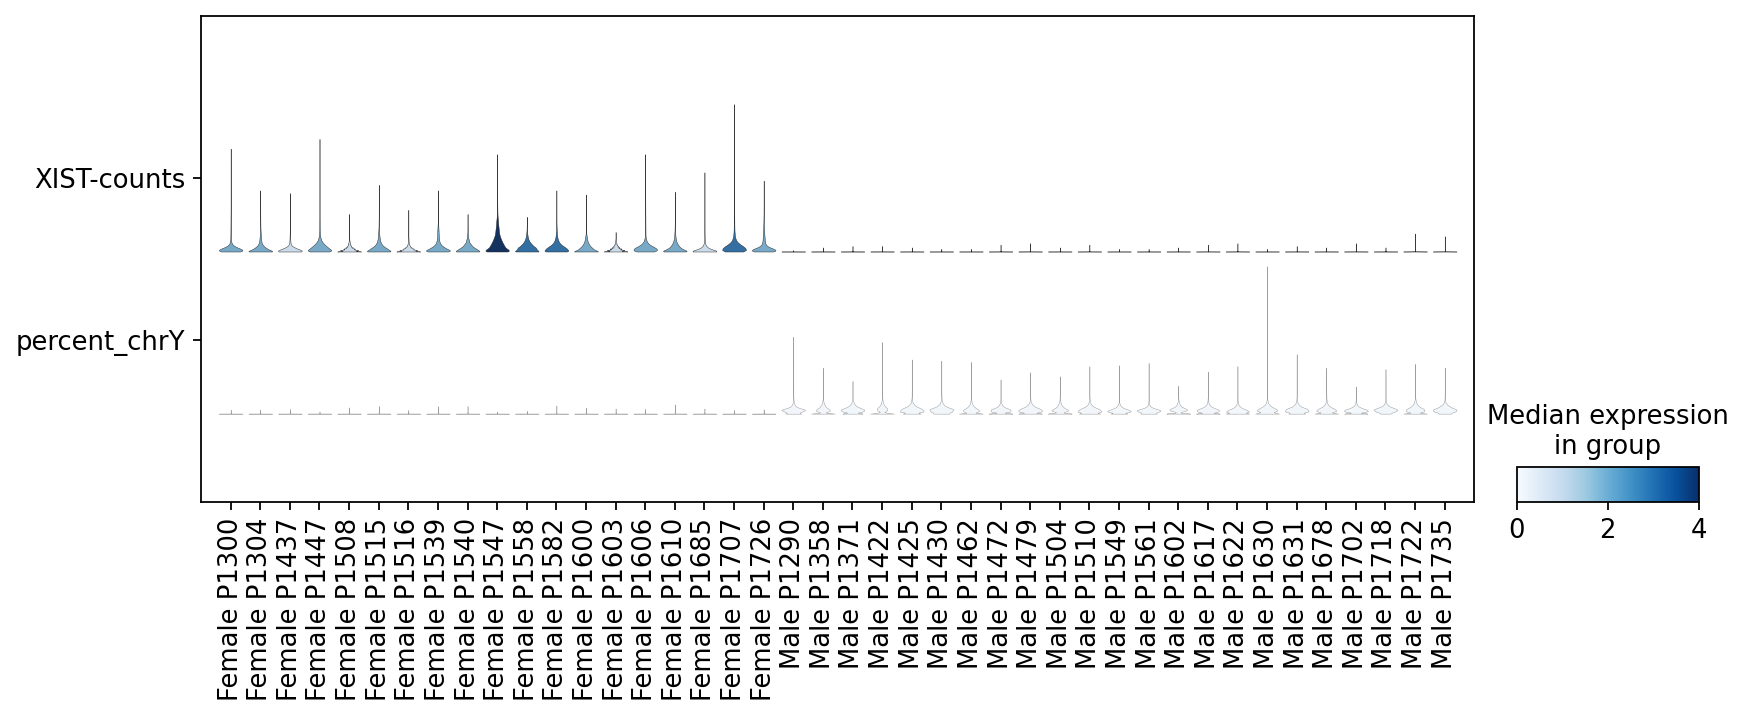

In [15]:
data = Chaffin
chrY_genes = data.var_names.intersection(annot.index[annot.chromosome_name == "Y"])
data.obs['percent_chrY'] = np.sum(data[:, chrY_genes].X, axis=1).A1 / np.sum(data.X, axis=1).A1 * 100
data.obs["XIST-counts"] = data.X[:,data.var_names.str.match('XIST')].toarray()
data.obs["Gender"] = data.obs["Sex"].str.cat(data.obs["Donor"], sep=" ")
sc.pl.stacked_violin(data, ["XIST-counts", "percent_chrY"], jitter=0.4, groupby = "Gender", swap_axes=True, figsize=(12,4))

## König 2022

In [2]:
König = sc.read_h5ad("/rwthfs/rz/cluster/home/noco0013/projects/novo_postdoc/data/GSE183852_DCM_Nuclei.h5ad")
sc.pp.filter_cells(König, min_genes=300)
sc.pp.filter_genes(König, min_cells=5)

In [3]:
König

AnnData object with n_obs × n_vars = 220748 × 29484
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mito', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.0.03', 'SCT_snn_res.0.04', 'SCT_snn_res.0.05', 'SCT_snn_res.0.06', 'SCT_snn_res.0.07', 'SCT_snn_res.0.08', 'SCT_snn_res.0.09', 'SCT_snn_res.0.1', 'SCT_snn_res.0.2', 'SCT_snn_res.0.3', 'SCT_snn_res.0.4', 'SCT_snn_res.0.5', 'SCT_snn_res.0.6', 'SCT_snn_res.0.7', 'SCT_snn_res.0.8', 'SCT_snn_res.0.9', 'SCT_snn_res.1', 'seurat_clusters', 'Names', 'Condition', 'n_genes'
    var: 'name', 'n_cells'
    obsm: 'X_pca', 'X_tsne', 'X_umap'

In [4]:
König.X.data

array([1., 1., 1., ..., 1., 1., 1.], dtype=float32)

In [5]:
König.obs

,orig.ident,nCount_RNA,nFeature_RNA,percent.mito,nCount_SCT,nFeature_SCT,SCT_snn_res.0.03,SCT_snn_res.0.04,SCT_snn_res.0.05,SCT_snn_res.0.06,...,SCT_snn_res.0.5,SCT_snn_res.0.6,SCT_snn_res.0.7,SCT_snn_res.0.8,SCT_snn_res.0.9,SCT_snn_res.1,seurat_clusters,Names,Condition,n_genes
H_ZC-11-292_TAAGTGCAGCAGGTCA,H_ZC-11-292,1245.0,919,0.481928,1626.0,919,5,5,5,5,...,5,5,5,8,8,7,7,Endocardium,Donor,919
H_ZC-11-292_ACAGCCGGTCATACTG,H_ZC-11-292,1464.0,1004,0.341530,1698.0,1004,5,5,5,5,...,5,5,5,12,13,13,13,Endocardium,Donor,1004
H_ZC-11-292_AACTCCCTCTTTAGTC,H_ZC-11-292,1668.0,1158,0.239808,1803.0,1158,5,5,5,5,...,5,5,5,8,8,7,7,Endocardium,Donor,1158
H_ZC-11-292_CTGATCCGTTATTCTC,H_ZC-11-292,2696.0,1562,0.222552,2554.0,1562,5,5,5,5,...,5,5,5,8,8,7,7,Endocardium,Donor,1562
H_ZC-11-292_GCACTCTTCTCGTATT,H_ZC-11-292,1947.0,1222,0.513611,1994.0,1222,5,5,5,5,...,5,5,5,8,8,7,7,Endocardium,Donor,1222
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TWCM-14-173_CGTAGGCGTGGTACAG,TWCM-14-173,4977.0,2078,0.602773,3202.0,1943,9,9,9,9,...,17,17,19,24,24,25,25,Epicardium,Donor,2078
TWCM-14-173_CGATGGCCATCATCCC,TWCM-14-173,2899.0,1171,0.862366,2575.0,1171,9,9,9,9,...,17,17,19,24,24,25,25,Epicardium,Donor,1171
TWCM-14-173_AAAGTAGTCGACCAGC,TWCM-14-173,1635.0,891,0.489297,1816.0,891,9,9,9,9,...,17,17,19,24,24,25,25,Epicardium,Donor,891
TWCM-14-173_CAGAATCCAGTACACT,TWCM-14-173,1937.0,1130,0.619515,1983.0,1130,9,9,9,9,...,17,17,19,24,24,25,25,Epicardium,Donor,1130


In [6]:
del König.obsm

In [7]:
König.obs.drop(["nCount_SCT","nFeature_SCT","SCT_snn_res.0.03","SCT_snn_res.0.04","SCT_snn_res.0.05","SCT_snn_res.0.06","SCT_snn_res.0.07","SCT_snn_res.0.08","SCT_snn_res.0.09","SCT_snn_res.0.1","SCT_snn_res.0.2","SCT_snn_res.0.3","SCT_snn_res.0.4","SCT_snn_res.0.5", "SCT_snn_res.0.6", "SCT_snn_res.0.7","SCT_snn_res.0.8","SCT_snn_res.0.9","SCT_snn_res.1","seurat_clusters"], axis=1, inplace=True)

In [8]:
meta = pd.read_csv("Meta_data_Koenig_.csv", index_col=0)
for col in meta:
    König.obs[col] = meta[col]

In [9]:
König.obs.drop(['orig.ident', "percent.mito"], axis=1, inplace=True)
König.obs

,nCount_RNA,nFeature_RNA,Names,Condition,n_genes,Technology,Assay,Study,Tissue,Donor,Age,Sex,BMI,Hypertension,Diabetes,Ischemia,Death,Doublets
H_ZC-11-292_TAAGTGCAGCAGGTCA,1245,919,Endocardium,Healthy,919,5v1,Nuclei,König 2022,Left Ventricle,Kö_H_ZC-11-292,60-69,Male,24.70,Hypertension,Healthy,Healthy,DBD,0.00
H_ZC-11-292_ACAGCCGGTCATACTG,1464,1004,Endocardium,Healthy,1004,5v1,Nuclei,König 2022,Left Ventricle,Kö_H_ZC-11-292,60-69,Male,24.70,Hypertension,Healthy,Healthy,DBD,0.00
H_ZC-11-292_AACTCCCTCTTTAGTC,1668,1158,Endocardium,Healthy,1158,5v1,Nuclei,König 2022,Left Ventricle,Kö_H_ZC-11-292,60-69,Male,24.70,Hypertension,Healthy,Healthy,DBD,0.02
H_ZC-11-292_CTGATCCGTTATTCTC,2696,1562,Endocardium,Healthy,1562,5v1,Nuclei,König 2022,Left Ventricle,Kö_H_ZC-11-292,60-69,Male,24.70,Hypertension,Healthy,Healthy,DBD,0.02
H_ZC-11-292_GCACTCTTCTCGTATT,1947,1222,Endocardium,Healthy,1222,5v1,Nuclei,König 2022,Left Ventricle,Kö_H_ZC-11-292,60-69,Male,24.70,Hypertension,Healthy,Healthy,DBD,0.08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TWCM-14-173_CGTAGGCGTGGTACAG,4977,2078,Epicardium,Healthy,2078,5v1,Nuclei,König 2022,Left Ventricle,Kö_TWCM-14-173,60-69,Female,22.51,normal,Healthy,Healthy,DBD,0.00
TWCM-14-173_CGATGGCCATCATCCC,2899,1171,Epicardium,Healthy,1171,5v1,Nuclei,König 2022,Left Ventricle,Kö_TWCM-14-173,60-69,Female,22.51,normal,Healthy,Healthy,DBD,0.02
TWCM-14-173_AAAGTAGTCGACCAGC,1635,891,Epicardium,Healthy,891,5v1,Nuclei,König 2022,Left Ventricle,Kö_TWCM-14-173,60-69,Female,22.51,normal,Healthy,Healthy,DBD,0.00
TWCM-14-173_CAGAATCCAGTACACT,1937,1130,Epicardium,Healthy,1130,5v1,Nuclei,König 2022,Left Ventricle,Kö_TWCM-14-173,60-69,Female,22.51,normal,Healthy,Healthy,DBD,0.08


In [10]:
König.obs.rename(columns={'Names': 'Cell_type'}, inplace=True)

In [11]:
#library("rtracklayer")
#gtf <- import("Homo_sapiens.GRCh38.84.gtf")
#gtf_38_84 <- mcols(gtf)[,c("gene_id","gene_name")]
#gtf_38_84 <- unique(gtf_38_84)

#del König.var["name"]
var_ID = pd.read_csv("gtf_38_84.csv", index_col=1)
#gene_names = var_ID.loc[var_ID.index.isin(König.var_names)]
var_names_unique = pd.Series(König.var_names).drop_duplicates().tolist()

# Merge var_ID with ONLY matching unique gene names to get gene IDs
gene_names = var_ID[var_ID.index.isin(var_names_unique)]
gene_names = gene_names[~gene_names.index.duplicated(keep=False)]

# Merge gene_names with König.var using var_names
König.var = pd.merge(König.var, gene_names, left_index=True, right_index=True, how='left')


König.var_names = König.var["gene_id"]
König.var

,name,n_cells,gene_id
gene_id,,,
ENSG00000243485,RP11-34P13.3,55,ENSG00000243485
ENSG00000238009,RP11-34P13.7,2383,ENSG00000238009
ENSG00000239906,RP11-34P13.14,47,ENSG00000239906
ENSG00000241599,RP11-34P13.9,5,ENSG00000241599
ENSG00000279928,FO538757.3,90,ENSG00000279928
...,...,...,...
ENSG00000278633,AC023491.2,12,ENSG00000278633
ENSG00000276345,AC004556.1,966,ENSG00000276345
ENSG00000275063,AC233755.1,14,ENSG00000275063


In [12]:
vars_with_na = König.var.index[König.var.isna().any(axis=1)]
König = König[:, ~König.var.index.isin(vars_with_na)]

In [14]:
König.write("/rwthfs/rz/cluster/home/noco0013/projects/novo_postdoc/data/Heart/König_2022_raw.h5ad")

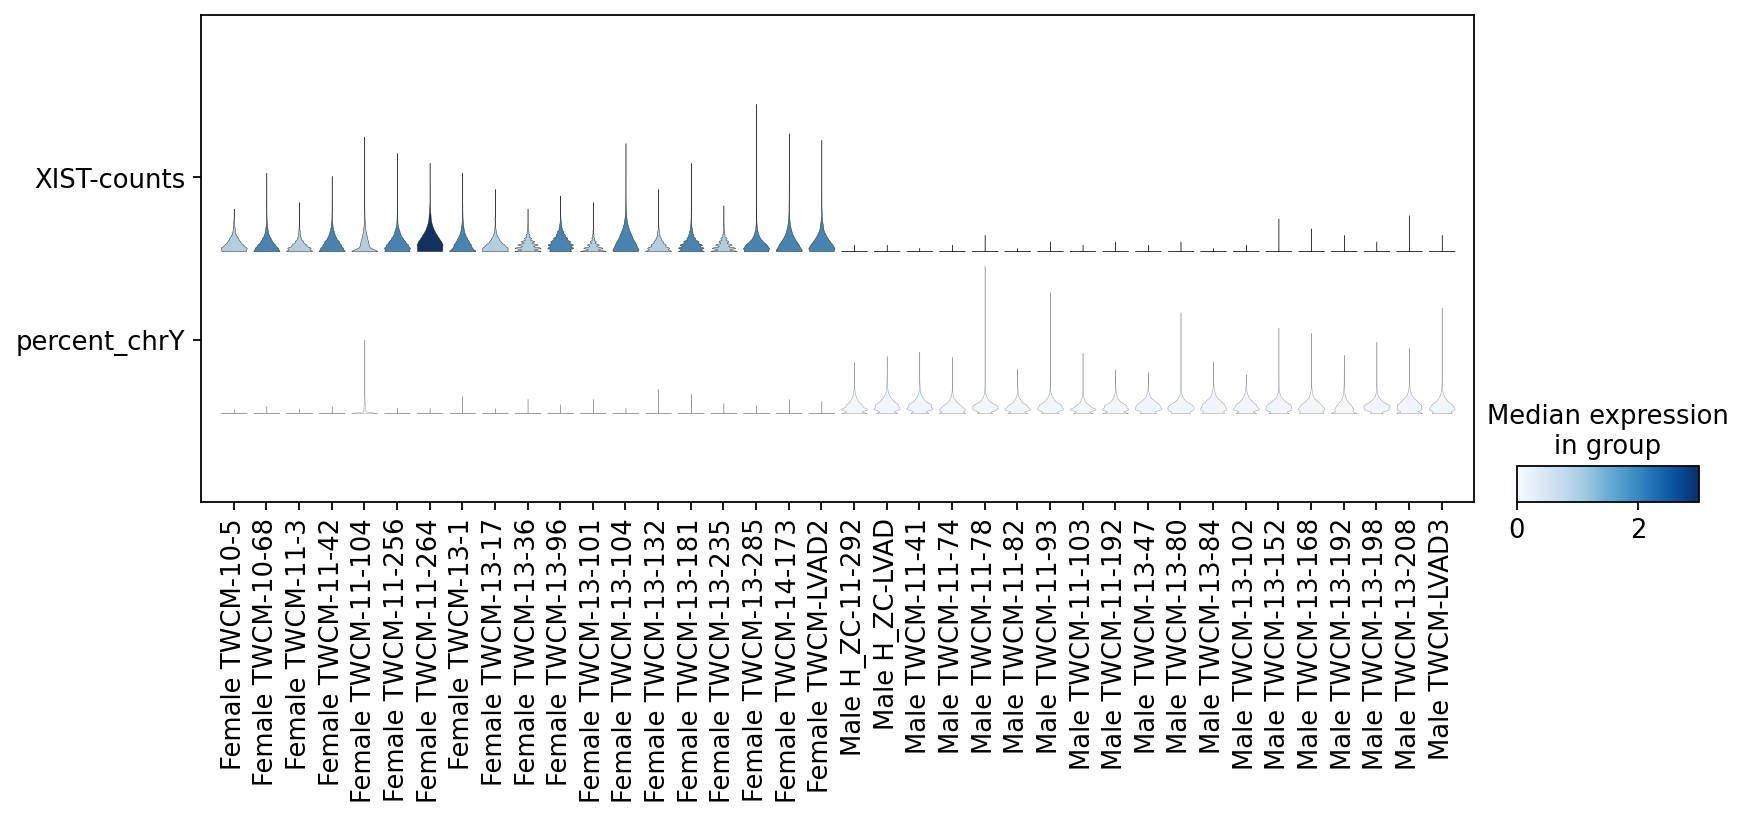

In [23]:
data = König
chrY_genes = data.var_names.intersection(annot.index[annot.chromosome_name == "Y"])
data.obs['percent_chrY'] = np.sum(data[:, chrY_genes].X, axis=1).A1 / np.sum(data.X, axis=1).A1 * 100
data.obs["XIST-counts"] = data.X[:,data.var_names.str.match('XIST')].toarray()
data.obs["Gender"] = data.obs["Sex"].str.cat(data.obs["Donor"], sep=" ")
sc.pl.stacked_violin(data, ["XIST-counts", "percent_chrY"], jitter=0.4, groupby = "Gender", swap_axes=True, figsize=(12,4))

## Kuppe 2022

In [ ]:
Kuppe = sc.read_h5ad("Kuppe_2022.h5ad")
sc.pp.filter_cells(Kuppe, min_genes=300)
sc.pp.filter_genes(Kuppe, min_cells=5)

In [89]:
Kuppe = Kuppe.raw.to_adata()

In [90]:
Kuppe.X.data

array([1., 1., 1., ..., 1., 1., 1.], dtype=float32)

In [91]:
Kuppe

AnnData object with n_obs × n_vars = 191795 × 29046
    obs: 'sample', 'n_counts', 'n_genes', 'percent_mito', 'doublet_score', 'dissociation_score', 'cell_type_original', 'patient_region_id', 'donor_id', 'patient_group', 'major_labl', 'final_cluster', 'assay_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'is_primary_data', 'organism_ontology_term_id', 'sex_ontology_term_id', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'suspension_type', 'cell_type', 'assay', 'disease', 'organism', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage'
    var: 'feature_name', 'feature_reference', 'feature_biotype'
    uns: 'X_approximate_distribution', 'batch_condition', 'cell_type_colors', 'cell_type_original_colors', 'default_embedding', 'schema_version', 'title'
    obsm: 'X_harmony', 'X_pca', 'X_umap'

In [92]:
del Kuppe.uns
del Kuppe.obsm

In [93]:
meta = pd.read_csv("Meta_data_Kuppe_.csv", index_col=0)
for col in meta:
    Kuppe.obs[col] = meta[col]

In [94]:
Kuppe.obs.drop(['sample', 'n_counts', 'n_genes', 'percent_mito', 'doublet_score', 'dissociation_score', 'cell_type_original', 'patient_region_id', 'donor_id', 'patient_group', 'major_labl', 'final_cluster', 'assay_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'is_primary_data', 'organism_ontology_term_id', 'sex_ontology_term_id', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'suspension_type', 'cell_type', 'assay', 'disease', 'organism', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage'], axis=1, inplace=True)

In [129]:
Kuppe.write("Kuppe_2022_raw.h5ad")

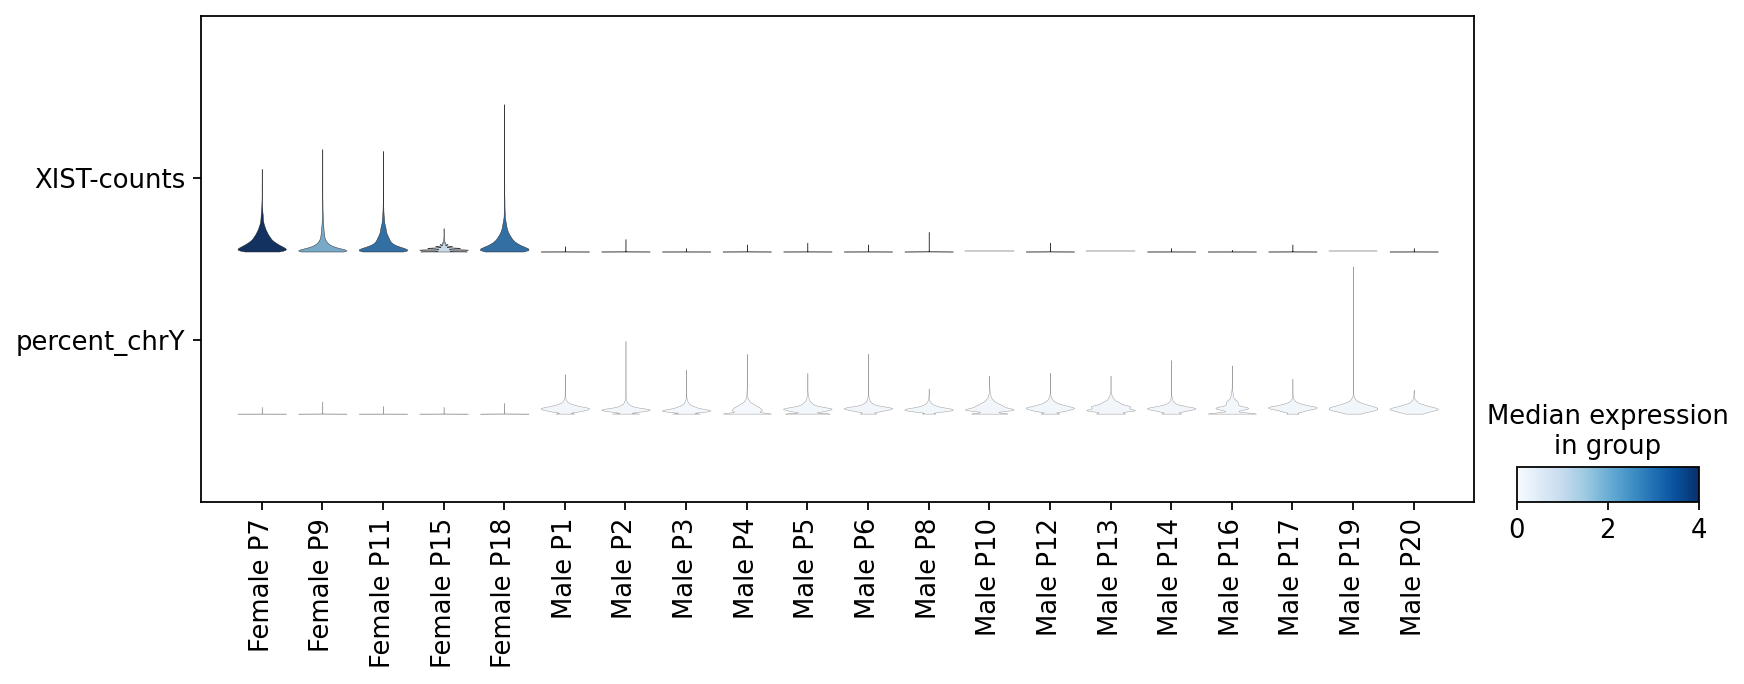

In [32]:
Kuppe.var.index = Kuppe.var["feature_name"]
data = Kuppe
chrY_genes = data.var_names.intersection(annot.index[annot.chromosome_name == "Y"])
data.obs['percent_chrY'] = np.sum(data[:, chrY_genes].X, axis=1).A1 / np.sum(data.X, axis=1).A1 * 100
data.obs["XIST-counts"] = data.X[:,data.var_names.str.match('XIST')].toarray()
data.obs["Gender"] = data.obs["Sex"].str.cat(data.obs["Donor"], sep=" ")
sc.pl.stacked_violin(data, ["XIST-counts", "percent_chrY"], jitter=0.4, groupby = "Gender", swap_axes=True, figsize=(12,4))

## Litvinukova

In [155]:
Litvinukova = sc.read_h5ad("/rwthfs/rz/cluster/home/noco0013/projects/novo_postdoc/data/global_raw.h5ad")
sc.pp.filter_cells(Litvinukova, min_genes=300)
sc.pp.filter_genes(Litvinukova, min_cells=5)

In [156]:
Litvinukova = Litvinukova[(Litvinukova.obs.region == "AX")|(Litvinukova.obs.region == "LV")|(Litvinukova.obs.region == "SP")]
Litvinukova = Litvinukova[(Litvinukova.obs.cell_source == "Harvard-Nuclei")|(Litvinukova.obs.cell_source == "Sanger-Nuclei")]


In [157]:
Litvinukova.X.data

array([2., 1., 1., ..., 1., 1., 1.], dtype=float32)

In [158]:
del Litvinukova.uns
del Litvinukova.obsm

In [159]:
meta = pd.read_csv("Meta_data_Litvinukova_.csv", index_col=0)
for col in meta:
    Litvinukova.obs[col] = meta[col]

In [160]:
Litvinukova.obs["Subcluster"] = Litvinukova.obs['cell_states']

In [161]:
Litvinukova.obs.drop(['NRP', 'age_group', 'cell_source', 'cell_type', 'donor', 'gender', 'percent_mito', 'percent_ribo', 'region', 'sample', 'n_counts', 'n_genes', 'scrublet_score', 'source', 'type', 'version', 'Used', 'cell_states'], axis=1, inplace=True)

In [162]:
Litvinukova.obs

,Cell_type,Sex,Assay,Death,nCount_RNA,nFeature_RNA,Technology,Age,Study,Ischemia,Condition,Donor,BMI,Hypertension,Diabetes,Tissue,Doublets,Subcluster
AAACCCAAGAACGCGT-1-H0015_apex,Smooth_muscle_cells,Female,Nuclei,DBD,688,480,3v3,50-59,Litvinukova 2020,Healthy,Healthy,Li_H5,22.51,normal,Healthy,Apex,0.00,SMC1_basic
AAACCCAAGCAAACAT-1-H0015_apex,Ventricular_Cardiomyocyte,Female,Nuclei,DBD,3216,1365,3v3,50-59,Litvinukova 2020,Healthy,Healthy,Li_H5,22.51,normal,Healthy,Apex,0.48,vCM1
AAACCCAAGCTACTGT-1-H0015_apex,Ventricular_Cardiomyocyte,Female,Nuclei,DBD,3182,1521,3v3,50-59,Litvinukova 2020,Healthy,Healthy,Li_H5,22.51,normal,Healthy,Apex,1.00,vCM1
AAACCCAGTACCGCGT-1-H0015_apex,Pericytes,Female,Nuclei,DBD,1202,726,3v3,50-59,Litvinukova 2020,Healthy,Healthy,Li_H5,22.51,normal,Healthy,Apex,0.06,PC2_atria
AAACCCATCAAACCCA-1-H0015_apex,Ventricular_Cardiomyocyte,Female,Nuclei,DBD,3804,1584,3v3,50-59,Litvinukova 2020,Healthy,Healthy,Li_H5,22.51,normal,Healthy,Apex,0.62,vCM2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGGTTTCCGCTGTT-1-HCAHeart8287128,Pericytes,Female,Nuclei,DCD,1133,708,3v3,60-69,Litvinukova 2020,Healthy,Healthy,Li_D11,27.51,normal,Healthy,Apex,0.12,PC1_vent
TTTGTTGAGATGCTGG-1-HCAHeart8287128,Pericytes,Female,Nuclei,DCD,1440,877,3v3,60-69,Litvinukova 2020,Healthy,Healthy,Li_D11,27.51,normal,Healthy,Apex,0.34,PC2_atria
TTTGTTGAGGCTCCCA-1-HCAHeart8287128,Ventricular_Cardiomyocyte,Female,Nuclei,DCD,6342,2157,3v3,60-69,Litvinukova 2020,Healthy,Healthy,Li_D11,27.51,normal,Healthy,Apex,0.78,vCM2
TTTGTTGAGTGTTGAA-1-HCAHeart8287128,Ventricular_Cardiomyocyte,Female,Nuclei,DCD,1159,798,3v3,60-69,Litvinukova 2020,Healthy,Healthy,Li_D11,27.51,normal,Healthy,Apex,0.36,vCM1


In [167]:
Litvinukova.var['gene_ids'] = Litvinukova.var['gene_ids-Harvard-Nuclei']
Litvinukova.var.drop(["gene_ids-Harvard-Nuclei", "feature_types-Harvard-Nuclei", "gene_ids-Sanger-Nuclei", "feature_types-Sanger-Nuclei","gene_ids-Sanger-Cells", "feature_types-Sanger-Cells", "gene_ids-Sanger-CD45", "feature_types-Sanger-CD45"], axis=1, inplace=True)

,n_cells,gene_ids
MIR1302-2HG,19,ENSG00000243485
AL627309.1,5454,ENSG00000238009
AL627309.2,11,ENSG00000239906
AL732372.1,6,ENSG00000236601
AC114498.1,814,ENSG00000235146
...,...,...
BX072566.1,105,ENSG00000277630
AL354822.1,11767,ENSG00000278384
AC023491.2,15,ENSG00000278633
AC004556.1,3369,ENSG00000276345


In [168]:
# Convert the index to a column called 'gene_symbol' but and use gene_id instead
Litvinukova.var['gene_symbol'] = Litvinukova.var.index
Litvinukova.var.index = Litvinukova.var['gene_ids']
Litvinukova.var.drop(columns=['gene_ids'], inplace=True)
Litvinukova.var

,n_cells,gene_symbol
gene_ids,,
ENSG00000243485,19,MIR1302-2HG
ENSG00000238009,5454,AL627309.1
ENSG00000239906,11,AL627309.2
ENSG00000236601,6,AL732372.1
ENSG00000235146,814,AC114498.1
...,...,...
ENSG00000277630,105,BX072566.1
ENSG00000278384,11767,AL354822.1
ENSG00000278633,15,AC023491.2


In [169]:
Litvinukova.write("/rwthfs/rz/cluster/home/noco0013/projects/novo_postdoc/data/Heart/Litvinukova_2021_raw.h5ad")

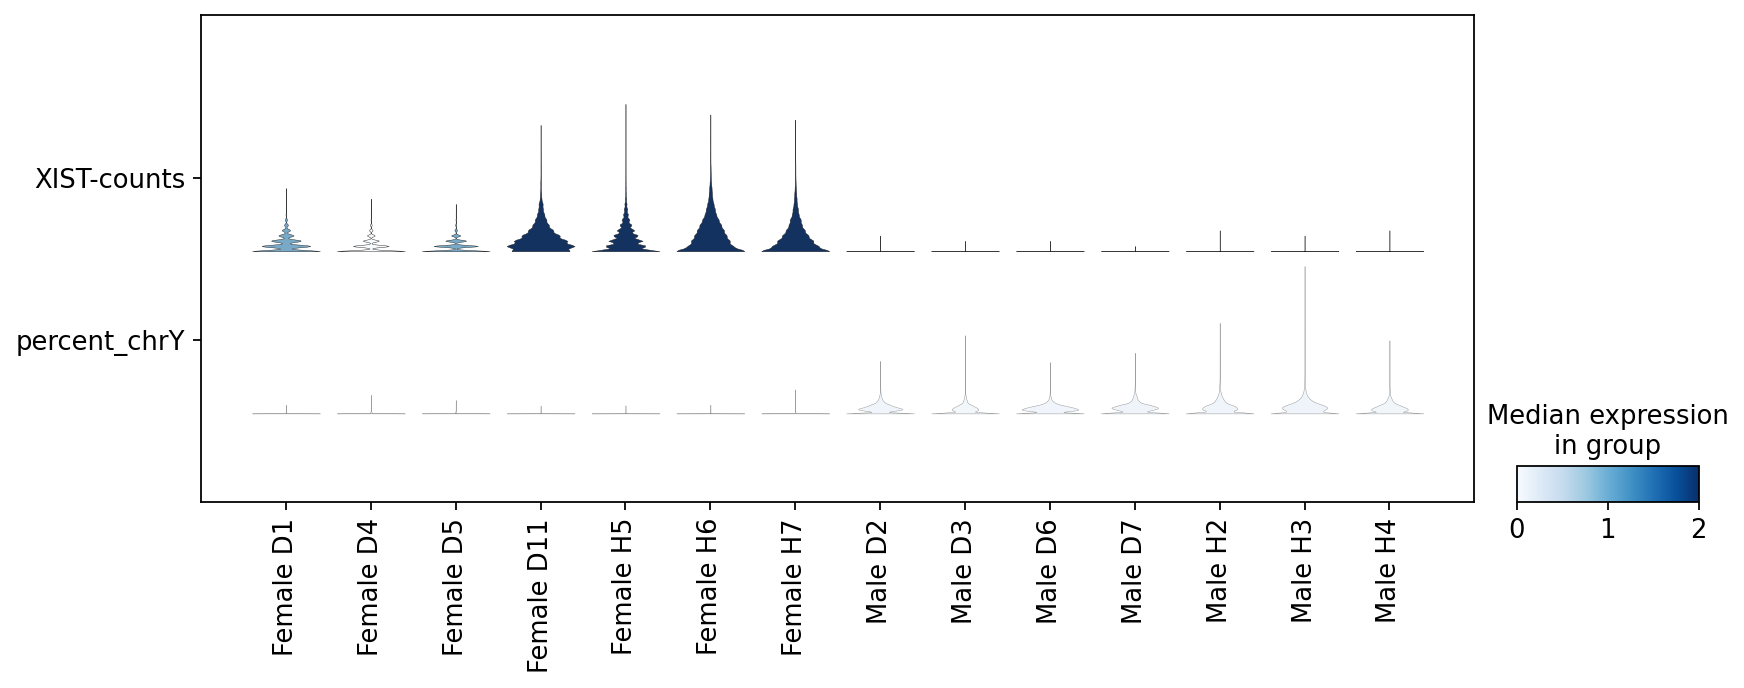

In [41]:
data = Litvinukova
chrY_genes = data.var_names.intersection(annot.index[annot.chromosome_name == "Y"])
data.obs['percent_chrY'] = np.sum(data[:, chrY_genes].X, axis=1).A1 / np.sum(data.X, axis=1).A1 * 100
data.obs["XIST-counts"] = data.X[:,data.var_names.str.match('XIST')].toarray()
data.obs["Gender"] = data.obs["Sex"].str.cat(data.obs["Donor"], sep=" ")
sc.pl.stacked_violin(data, ["XIST-counts", "percent_chrY"], jitter=0.4, groupby = "Gender", swap_axes=True, figsize=(12,4))

## Reichart 2022

In [2]:
Reichart = sc.read_h5ad("/rwthfs/rz/cluster/home/noco0013/projects/novo_postdoc/data/local.h5ad")

In [3]:
Reichart = Reichart[Reichart.obs.Region_x == "LV"]

In [4]:
Reichart

View of AnnData object with n_obs × n_vars = 650358 × 33234
    obs: 'Sample', 'donor_id', 'Region_x', 'Primary.Genetic.Diagnosis', 'n_genes', 'n_counts', 'percent_mito', 'percent_ribo', 'scrublet_score_z', 'scrublet_score_log', 'solo_score', 'cell_states', 'Assigned', 'self_reported_ethnicity_ontology_term_id', 'disease_ontology_term_id', 'cell_type_ontology_term_id', 'sex_ontology_term_id', 'assay_ontology_term_id', 'organism_ontology_term_id', 'is_primary_data', 'tissue_ontology_term_id', 'development_stage_ontology_term_id', 'suspension_type', 'cell_type', 'assay', 'disease', 'organism', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage'
    var: 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype'
    uns: 'cell_states_colors', 'cell_type_colors', 'cell_type_ontology_term_id_colors', 'leiden', 'neighbors', 'pca', 'schema_version', 'title', 'umap'
    obsm: 'X_pca', 'X_umap'

In [5]:
Reichart = Reichart.raw.to_adata()

In [6]:
Reichart.X.data

array([1., 1., 1., ..., 1., 2., 1.], dtype=float32)

In [7]:
del Reichart.uns
del Reichart.obsm

In [8]:
meta = pd.read_csv("Meta_data_Reichart_.csv", index_col=0)
meta.index = meta.index.astype(str)
for col in meta:
    Reichart.obs[col] = meta[col]

In [9]:
Reichart.obs["Cell_type"] = Reichart.obs['cell_type']
Reichart.obs["Subcluster"] = Reichart.obs['cell_states']

In [12]:
Reichart.obs.drop(['Sample', 'Primary.Genetic.Diagnosis', 'nFeaturess_RNA', 'nCounts_RNA', 'percent_mito', 'percent_ribo', 'scrublet_score_z', 'scrublet_score_log', 'solo_score', 'disease', 'organism', 'cell_type', 'cell_states', "self_reported_ethnicity"], axis=1, inplace=True)

In [14]:
Reichart.obs.drop(['donor_id', 'Region_x', 'n_genes', 'n_counts', 'Assigned',
       'self_reported_ethnicity_ontology_term_id', 'disease_ontology_term_id',
       'cell_type_ontology_term_id', 'sex_ontology_term_id',
       'assay_ontology_term_id', 'organism_ontology_term_id',
       'is_primary_data', 'tissue_ontology_term_id',
       'development_stage_ontology_term_id', 'suspension_type', 'assay', 'sex',
       'tissue', 'development_stage'], axis=1, inplace=True)

In [16]:
Reichart.obs

,Tissue,nCount_RNA,nFeature_RNA,Technology,Assay,Study,Sex,Donor,Age,Condition,Death,BMI,Hypertension,Diabetes,Genotype,Doublets,Cell_type,Subcluster
2428,interventricular septum,905,647,3v3,Nuclei,Reichart 2022,Male,Re_H3,50-59,Healthy,DBD,27.51,normal,Healthy,NaN,0.08,mural cell,SMC1.2
2429,interventricular septum,2656,1476,3v3,Nuclei,Reichart 2022,Male,Re_H3,50-59,Healthy,DBD,27.51,normal,Healthy,NaN,0.38,cardiac muscle cell,vCM1.0
2430,interventricular septum,1157,716,3v3,Nuclei,Reichart 2022,Male,Re_H3,50-59,Healthy,DBD,27.51,normal,Healthy,NaN,0.00,cardiac muscle cell,vCM2
2431,interventricular septum,1054,752,3v3,Nuclei,Reichart 2022,Male,Re_H3,50-59,Healthy,DBD,27.51,normal,Healthy,NaN,0.08,endothelial cell,EC8.0
2432,interventricular septum,601,427,3v3,Nuclei,Reichart 2022,Male,Re_H3,50-59,Healthy,DBD,27.51,normal,Healthy,NaN,0.00,mural cell,PC1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
878977,heart left ventricle,4190,2288,3v3,Nuclei,Reichart 2022,Female,Re_IC_H04,60-69,DCM,DCM,21.40,normal,Healthy,PVneg,0.54,endothelial cell,EC2.0
878978,heart left ventricle,516,446,3v3,Nuclei,Reichart 2022,Female,Re_IC_H04,60-69,DCM,DCM,21.40,normal,Healthy,PVneg,0.52,fibroblast of cardiac tissue,vFB3
878979,heart left ventricle,6419,2747,3v3,Nuclei,Reichart 2022,Female,Re_IC_H04,60-69,DCM,DCM,21.40,normal,Healthy,PVneg,0.34,fibroblast of cardiac tissue,vFB2
878980,heart left ventricle,6581,2614,3v3,Nuclei,Reichart 2022,Female,Re_IC_H04,60-69,DCM,DCM,21.40,normal,Healthy,PVneg,1.28,native cell,PC_lowQC


In [17]:
sc.pp.filter_cells(Reichart, min_genes=300)
sc.pp.filter_genes(Reichart, min_cells=5)

In [18]:
Reichart = Reichart[Reichart.obs["Age"] != "0-9"]
Reichart = Reichart[Reichart.obs["Age"] != "10-19"]

In [21]:
Reichart.var

,feature_name,feature_reference,feature_biotype,n_cells
gene_ids,,,,
ENSG00000243485,MIR1302-2HG,NCBITaxon:9606,gene,37
ENSG00000238009,RP11-34P13.7,NCBITaxon:9606,gene,12981
ENSG00000239906,RP11-34P13.14,NCBITaxon:9606,gene,24
ENSG00000241599,RP11-34P13.9,NCBITaxon:9606,gene,10
ENSG00000236601,RP4-669L17.2,NCBITaxon:9606,gene,15
...,...,...,...,...
ENSG00000277630,ENSG00000277630.4,NCBITaxon:9606,gene,119
ENSG00000278384,ENSG00000278384.1,NCBITaxon:9606,gene,17423
ENSG00000278633,ENSG00000278633.1,NCBITaxon:9606,gene,14


In [20]:
Reichart.write("/rwthfs/rz/cluster/home/noco0013/projects/novo_postdoc/data/Reichart_2022_raw.h5ad")

In [64]:
Reichart.var.index = Reichart.var["feature_name"]
data = Reichart
chrY_genes = data.var_names.intersection(annot.index[annot.chromosome_name == "Y"])


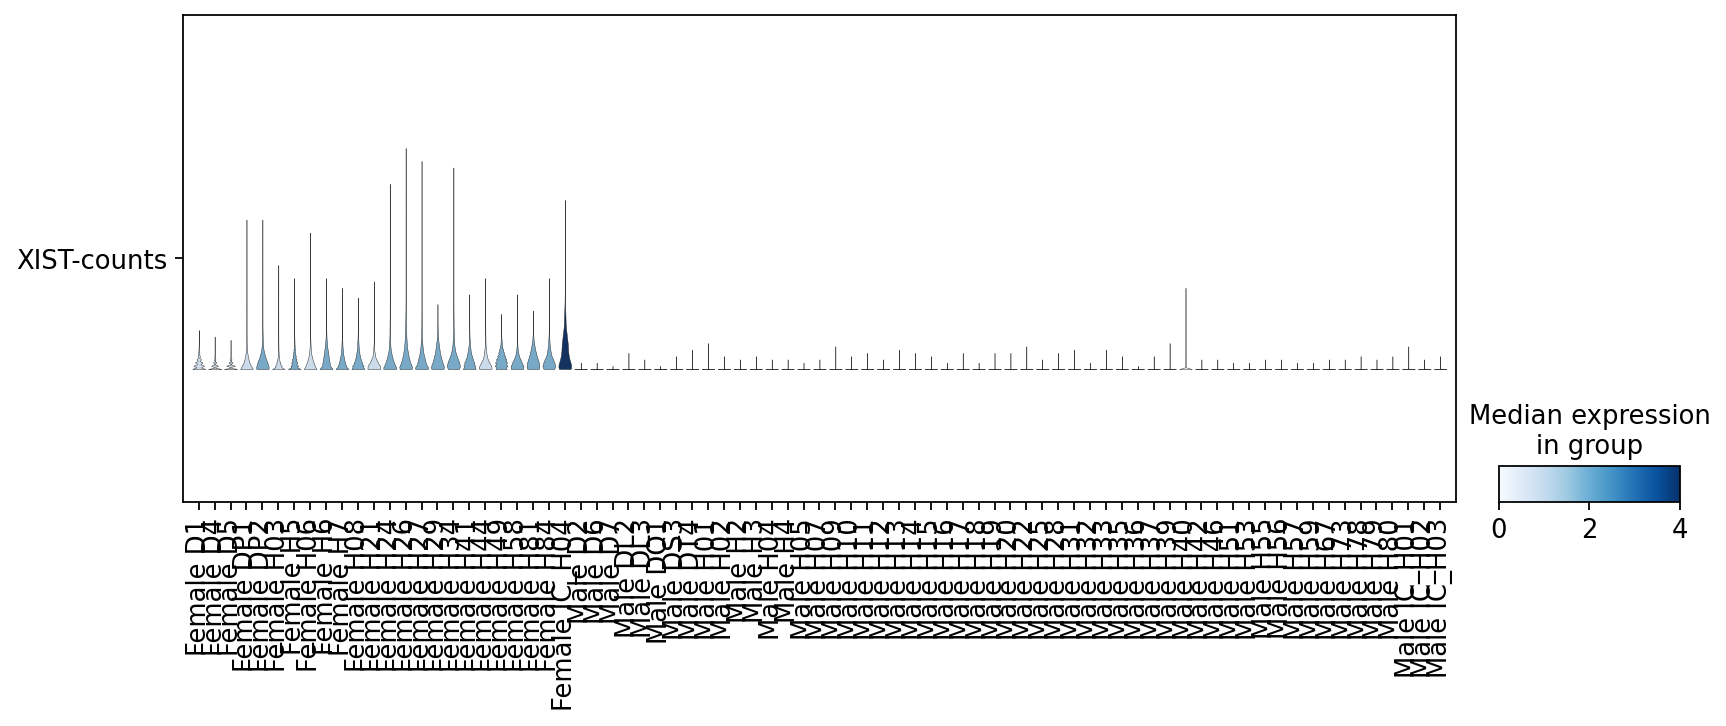

In [71]:
#data.obs['percent_chrY'] = np.sum(data[:, chrY_genes].X, axis=1).A1 / np.sum(data.X, axis=1).A1 * 100
data.obs["XIST-counts"] = data.X[:,data.var_names.str.match('XIST')].toarray()
data.obs["Gender"] = data.obs["Sex"].str.cat(data.obs["Donor"], sep=" ")
sc.pl.stacked_violin(data, ["XIST-counts", "percent_chrY"], jitter=0.4, groupby = "Gender", swap_axes=True, figsize=(12,4))

# Simonson 2023

In [143]:
Simonson = sc.read_h5ad("Simonson_2023.h5ad")
sc.pp.filter_cells(Simonson, min_genes=300)
sc.pp.filter_genes(Simonson, min_cells=5)

In [144]:
Simonson

AnnData object with n_obs × n_vars = 92342 × 28788
    obs: 'biosample_id', 'donor_id', 'disease', 'sex', 'age', 'cell_type_leiden0.5', 'sub_cluster', 'cellbender_ncount', 'cellbender_ngenes', 'cellranger_percent_mito', 'exon_prop', 'cellbender_entropy', 'cellranger_doublet_scores', 'n_genes'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells'
    obsm: 'X_umap'
    layers: 'cellranger_raw'

In [145]:
meta = pd.read_csv("Meta_data_Simonson_.csv", index_col=0)
for col in meta:
    Simonson.obs[col] = meta[col]

In [146]:
Simonson

AnnData object with n_obs × n_vars = 92342 × 28788
    obs: 'biosample_id', 'donor_id', 'disease', 'sex', 'age', 'cell_type_leiden0.5', 'sub_cluster', 'cellbender_ncount', 'cellbender_ngenes', 'cellranger_percent_mito', 'exon_prop', 'cellbender_entropy', 'cellranger_doublet_scores', 'n_genes', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'Donor', 'Cell_type', 'n_umi', 'entropy', 'doublet_score', 'Technology', 'Assay', 'Study', 'Tissue', 'Sex', 'Condition', 'Ischemia', 'Doublets'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells'
    obsm: 'X_umap'
    layers: 'cellranger_raw'

In [147]:
del Simonson.obsm
del Simonson.layers

In [148]:
Simonson.obs["Subcluster"] = Simonson.obs["sub_cluster"]

In [149]:
Simonson.obs.drop(['biosample_id', 'donor_id', 'disease', 'sex', 'age', 'cell_type_leiden0.5', 'sub_cluster', 'cellbender_ncount', 'cellbender_ngenes', 'cellranger_percent_mito', 'exon_prop', 'cellbender_entropy', 'cellranger_doublet_scores', 'orig.ident'], axis=1, inplace=True)

In [152]:
Simonson.obs

,n_genes,nCount_RNA,nFeature_RNA,Donor,Cell_type,n_umi,entropy,doublet_score,Technology,Assay,Study,Tissue,Sex,Condition,Ischemia,Doublets,Subcluster
TCCCACACAATAGTGA-1-0,4062,12534,4062,Si_P1364,cardiac muscle cell,12534,7.615499,0.084746,3v3,Nuclei,Simonson 2023,Left Ventricle,Female,Long-term ischemic,Ischemia,0.62,NaN
AATGCCACAACTTCTT-1-0,3962,12376,3962,Si_P1364,cardiac muscle cell,12376,7.598171,0.113490,3v3,Nuclei,Simonson 2023,Left Ventricle,Female,Long-term ischemic,Ischemia,0.58,NaN
ATTACTCCAATAGTAG-1-0,4178,12119,4178,Si_P1364,cardiac muscle cell,12119,7.687716,0.280000,3v3,Nuclei,Simonson 2023,Left Ventricle,Female,Long-term ischemic,Ischemia,0.96,NaN
ATCGTGACACCTGTCT-1-0,3935,11947,3934,Si_P1364,cardiac muscle cell,11948,7.632855,0.120000,3v3,Nuclei,Simonson 2023,Left Ventricle,Female,Long-term ischemic,Ischemia,0.68,NaN
CAGTTAGCAACCGCTG-1-0,4028,11903,4027,Si_P1364,cardiac muscle cell,11904,7.637542,0.101796,3v3,Nuclei,Simonson 2023,Left Ventricle,Female,Long-term ischemic,Ischemia,1.00,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TCGACGGGTCAAATCC-1-14,300,367,300,Si_P1801,cardiac endothelial cell,367,7.178795,0.024211,3v3,Nuclei,Simonson 2023,Left Ventricle,Male,Healthy,Healthy,0.02,EC-General capillary
GGCTTGGGTGCAATGG-1-14,362,414,362,Si_P1801,pericyte cell,414,7.752096,0.019980,3v3,Nuclei,Simonson 2023,Left Ventricle,Male,Healthy,Healthy,0.12,NaN
TCGGTCTCACTGATTG-1-14,359,416,359,Si_P1801,cardiac endothelial cell,416,7.658765,0.042308,3v3,Nuclei,Simonson 2023,Left Ventricle,Male,Healthy,Healthy,0.12,EC-General capillary
CCTTGTGTCGGAATTC-1-14,323,388,323,Si_P1801,cardiac endothelial cell,388,7.340663,0.034198,3v3,Nuclei,Simonson 2023,Left Ventricle,Male,Healthy,Healthy,0.02,EC-General capillary


In [153]:
# Convert the index to a column called 'gene_symbol' but and use gene_id instead
Simonson.var['gene_symbol'] = Simonson.var.index
Simonson.var.index = Simonson.var['gene_ids']
Simonson.var.drop(columns=['gene_ids'], inplace=True)
Simonson.var

,feature_types,genome,n_cells,gene_symbol
gene_ids,,,,
ENSG00000238009,Gene Expression,GRCh38-2020-A_premrna,360,AL627309.1
ENSG00000241860,Gene Expression,GRCh38-2020-A_premrna,530,AL627309.5
ENSG00000241599,Gene Expression,GRCh38-2020-A_premrna,7,AL627309.4
ENSG00000286448,Gene Expression,GRCh38-2020-A_premrna,98,AP006222.2
ENSG00000235146,Gene Expression,GRCh38-2020-A_premrna,19,AC114498.1
...,...,...,...,...
ENSG00000277666,Gene Expression,GRCh38-2020-A_premrna,6,AC136352.3
ENSG00000273554,Gene Expression,GRCh38-2020-A_premrna,53,AC136616.1
ENSG00000278633,Gene Expression,GRCh38-2020-A_premrna,5,AC023491.2


In [154]:
Simonson.write("Simonson_2023_raw.h5ad")